# Dictionary 275 on the third LeiData recording

Dictionary 275 (`randomized_builder_SOCAL_H_76_230427_014845.x`) has seven atoms learned on the GPL whitened spectrogram of `SOCAL_H_76_230427_014845.x.wav`, the third LeiData `.x.wav`. Each atom is correlated with that same spectrogram, 30 windows joined in time.

At spectrogram column `t` the stored value is the amplitude matching pursuit uses:

`alpha(t) = <S[:, t:t+W], A> / ||A||^2`

`S` is the whitened spectrogram, `A` is the atom, and `W` is the atom width in time bins. This is the sum of a valid correlation on each frequency row. Columns where the atom would run past the end of the recording are NaN.

The array is `scores` in `/home/yfreund/whale_processing/result/LeiData/dict275_014845_convolution/scores.npz`, shape `(7, 18270)`. Row `i` is atom `template_i`. Column `t` starts `t * 0.12288` seconds into the recording.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "analysis" / "GPL_Python" / "gpl_signal.py").is_file():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break

from analysis.GPL_Python.gpl_outputs import display_from_spwhiten

OUT = Path("/home/yfreund/whale_processing/result/LeiData/dict275_014845_convolution")
ATOM_DIR = Path(
    "/home/yfreund/whale_processing/result/reviewed_rebuilds/"
    "SOCAL_H_76_230427_014845.x/randomized_builder_20261026T212836022114"
)

bundle = np.load(OUT / "scores.npz")
scores = bundle["scores"]
widths = bundle["width"]
sec_per_bin = float(bundle["sec_per_bin"])
start_freq = float(bundle["start_freq"])
end_freq = float(bundle["end_freq"])
time_min = np.arange(scores.shape[1]) * sec_per_bin / 60.0
atoms = [np.load(ATOM_DIR / f"template_{i:03d}.npy") for i in range(scores.shape[0])]

print(f"scores {scores.shape}  bin {sec_per_bin:.5f} s  duration {scores.shape[1] * sec_per_bin / 60:.2f} min")
for i, width in enumerate(widths):
    row = scores[i]
    k = int(np.nanargmax(np.abs(row)))
    print(
        f"atom {i}  width {int(width)} bins ({int(width) * sec_per_bin:.2f} s)  "
        f"peak {row[k]:.4f} at {time_min[k]:.2f} min"
    )


scores (7, 18270)  bin 0.12288 s  duration 37.42 min
atom 0  width 20 bins (2.46 s)  peak 3.4197 at 9.46 min
atom 1  width 16 bins (1.97 s)  peak 5.9219 at 0.01 min
atom 2  width 12 bins (1.47 s)  peak 8.7740 at 0.01 min
atom 3  width 14 bins (1.72 s)  peak 6.7050 at 9.59 min
atom 4  width 12 bins (1.47 s)  peak 6.8344 at 9.60 min
atom 5  width 11 bins (1.35 s)  peak -9.0934 at 0.00 min
atom 6  width 10 bins (1.23 s)  peak 10.0337 at 9.61 min


## Atoms

Each image is the cube root of the absolute atom, the same display transform as the GPL spectrogram. Time runs left to right and frequency upward, from 10 Hz to 10 kHz.

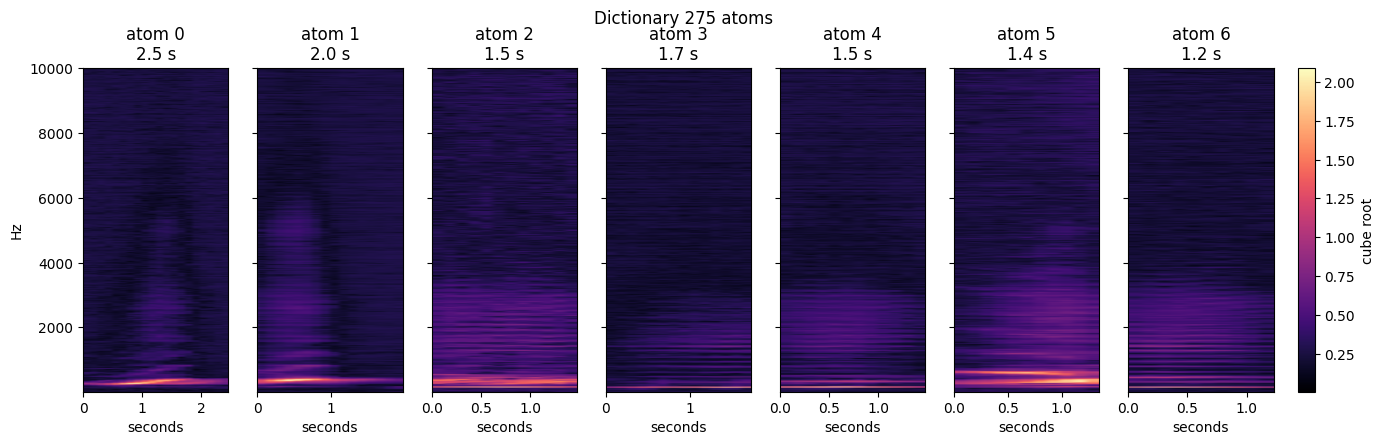

In [2]:
fig, axes = plt.subplots(1, len(atoms), figsize=(16, 4.2), sharey=True)
for i, (atom, ax) in enumerate(zip(atoms, axes)):
    shown = display_from_spwhiten(atom)
    extent = [0, atom.shape[1] * sec_per_bin, start_freq, end_freq]
    im = ax.imshow(shown, origin="lower", aspect="auto", cmap="magma", extent=extent)
    ax.set_title(f"atom {i}\n{atom.shape[1] * sec_per_bin:.1f} s")
    ax.set_xlabel("seconds")
axes[0].set_ylabel("Hz")
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="cube root")
fig.suptitle("Dictionary 275 atoms", y=1.02)
plt.show()


## Correlation from 9 to 11 minutes

`scores[i, t]` is the amplitude of atom `i` starting at time bin `t`. Every panel uses the same clock time, centered at 10 minutes.

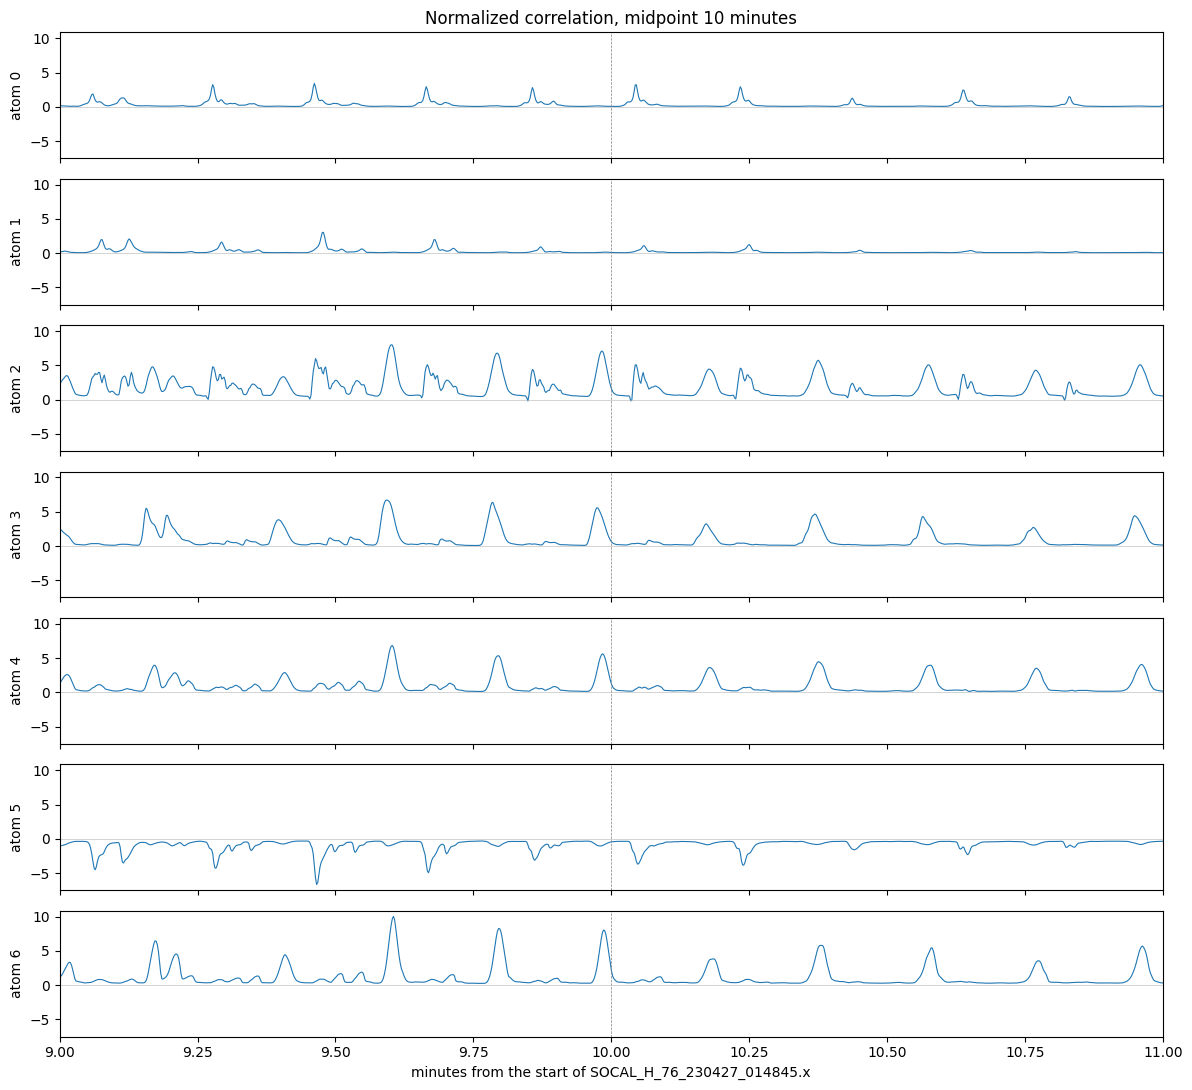

In [3]:
center_min = 10.0
half_min = 1.0
t_s = np.arange(scores.shape[1]) * sec_per_bin
mask = (t_s >= (center_min - half_min) * 60.0) & (t_s <= (center_min + half_min) * 60.0)
fig, axes = plt.subplots(scores.shape[0], 1, figsize=(12, 11), sharex=True, sharey=True)
for i, ax in enumerate(axes):
    ax.plot(t_s[mask] / 60.0, scores[i, mask], color="C0", lw=0.8)
    ax.axvline(center_min, color="0.5", lw=0.5, ls="--")
    ax.axhline(0, color="0.7", lw=0.4)
    ax.set_xlim(center_min - half_min, center_min + half_min)
    ax.set_ylabel(f"atom {i}")
axes[-1].set_xlabel("minutes from the start of SOCAL_H_76_230427_014845.x")
axes[0].set_title("Normalized correlation, midpoint 10 minutes")
fig.tight_layout()
plt.show()
